In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import duckdb
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    precision_score,
    recall_score,
    confusion_matrix,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

REPORT_DIR = ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

REPORT_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 42
SELECTED_THRESHOLD = 0.06
SELECTED_REVIEW_CAPACITY = 0.20

Project root: /Users/preeyapat/Desktop/Project-HomeCreditDefaultRisk


In [2]:
MODEL_PATH = ROOT / "models" / "lightgbm_model.joblib"

assert MODEL_PATH.exists(), (
    "Day 6 saved LightGBM model is missing."
)

saved = joblib.load(MODEL_PATH)

lgbm_model = saved["model"]
preprocessor = saved["preprocessor"]
features = saved["features"]

assert len(features) == 27

print("Model:", type(lgbm_model).__name__)
print("Original feature count:", len(features))
print("Best iteration:", lgbm_model.best_iteration_)

Model: LGBMClassifier
Original feature count: 27
Best iteration: 524


In [3]:
DATA_PATH = (
    ROOT / "data" / "processed" /
    "modeling_features.parquet"
)

con = duckdb.connect()

df = con.execute(
    "SELECT * FROM read_parquet(?)",
    [str(DATA_PATH)]
).df()

assert len(df) == 307511
assert df["SK_ID_CURR"].is_unique

X = df[features].copy()
y = df["TARGET"].astype(int)

numeric_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

X[numeric_cols] = X[numeric_cols].replace(
    [np.inf, -np.inf], np.nan
)

print("Dataset:", df.shape)
print("Positive rate:", f"{y.mean():.2%}")

Dataset: (307511, 143)
Positive rate: 8.07%


In [4]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

X_train, X_val, y_train, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.25,
    stratify=y_dev,
    random_state=RANDOM_STATE
)

assert len(X_train) == 184506
assert len(X_val) == 61502
assert len(X_test) == 61503

train_ids = set(df.loc[X_train.index, "SK_ID_CURR"])
val_ids = set(df.loc[X_val.index, "SK_ID_CURR"])
test_ids = set(df.loc[X_test.index, "SK_ID_CURR"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

print("PASS: Split sizes and applicant uniqueness verified.")

PASS: Split sizes and applicant uniqueness verified.


In [5]:
X_test_processed = preprocessor.transform(X_test)
X_val_processed = preprocessor.transform(X_val)

test_prob = lgbm_model.predict_proba(
    X_test_processed
)[:, 1]

val_prob = lgbm_model.predict_proba(
    X_val_processed
)[:, 1]

assert len(test_prob) == len(y_test)
assert np.isfinite(test_prob).all()
assert ((test_prob >= 0) & (test_prob <= 1)).all()

print("Test predictions generated successfully.")
print("Test positive cases:", int(y_test.sum()))

/Users/preeyapat/miniconda3/envs/homecredit/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Test predictions generated successfully.
Test positive cases: 4965


In [6]:
numeric_features = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "CNT_CHILDREN",
    "CNT_FAM_MEMBERS",
    "credit_income_ratio",
    "annuity_income_ratio",
    "employment_years",
    "employment_sentinel_flag",
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",
    "has_bureau_history",
    "bureau_total_accounts",
    "bureau_active_accounts",
    "bureau_closed_accounts",
    "bureau_total_credit",
    "bureau_total_debt",
    "bureau_total_overdue",
    "bureau_max_days_overdue",
    "bureau_avg_days_since_credit",
    "bureau_debt_credit_ratio"
]

categorical_features = [
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE",
    "NAME_HOUSING_TYPE",
    "FLAG_OWN_CAR",
    "FLAG_OWN_REALTY"
]

assert numeric_features + categorical_features == list(features)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    ))
])

logistic_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ],
    sparse_threshold=1.0
)

logistic_model = Pipeline([
    ("preprocessor", logistic_preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        solver="liblinear",
        random_state=RANDOM_STATE
    ))
])

logistic_model.fit(X_train, y_train)

logistic_val_prob = logistic_model.predict_proba(
    X_val
)[:, 1]

logistic_test_prob = logistic_model.predict_proba(
    X_test
)[:, 1]

print("Logistic Regression ready.")

Logistic Regression ready.


In [7]:
def evaluate_probabilities(y_true, probabilities):
    return {
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "Average Precision": average_precision_score(
            y_true, probabilities
        ),
        "Brier Score": brier_score_loss(
            y_true, probabilities
        )
    }

In [8]:
final_metrics = pd.DataFrame({
    "Logistic Regression": evaluate_probabilities(
        y_test, logistic_test_prob
    ),
    "LightGBM": evaluate_probabilities(
        y_test, test_prob
    )
}).T

display(final_metrics.round(4))

,ROC-AUC,Average Precision,Brier Score
Logistic Regression,0.7382,0.2179,0.0690
LightGBM,0.7487,0.2329,0.0684


In [9]:
validation_metrics = pd.DataFrame({
    "Logistic Regression": evaluate_probabilities(
        y_val, logistic_val_prob
    ),
    "LightGBM": evaluate_probabilities(
        y_val, val_prob
    )
}).T

comparison_rows = []

for model_name in final_metrics.index:
    for metric in [
        "ROC-AUC",
        "Average Precision",
        "Brier Score"
    ]:
        validation_value = validation_metrics.loc[
            model_name, metric
        ]
        test_value = final_metrics.loc[
            model_name, metric
        ]

        comparison_rows.append({
            "Model": model_name,
            "Metric": metric,
            "Validation": validation_value,
            "Test": test_value,
            "Test_Minus_Validation": (
                test_value - validation_value
            )
        })

generalization_df = pd.DataFrame(comparison_rows)

display(generalization_df.round(4))

,Model,Metric,Validation,Test,Test_Minus_Validation
0,Logistic Regression,ROC-AUC,0.7441,0.7382,-0.0059
1,Logistic Regression,Average Precision,0.2208,0.2179,-0.0029
2,Logistic Regression,Brier Score,0.0688,0.0690,0.0002
3,LightGBM,ROC-AUC,0.7541,0.7487,-0.0053
4,LightGBM,Average Precision,0.2373,0.2329,-0.0043
5,LightGBM,Brier Score,0.0681,0.0684,0.0003


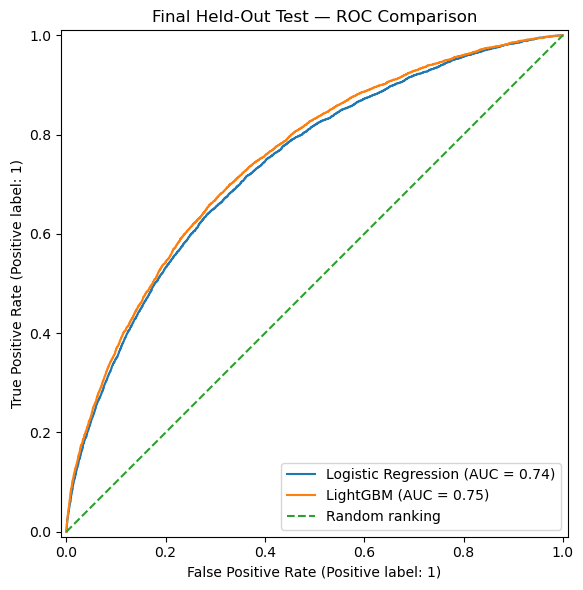

In [10]:
fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test,
    logistic_test_prob,
    name="Logistic Regression",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test,
    test_prob,
    name="LightGBM",
    ax=ax
)

ax.plot(
    [0, 1], [0, 1],
    "--",
    label="Random ranking"
)

ax.set_title("Final Held-Out Test — ROC Comparison")
ax.legend()

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "day13_test_roc.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

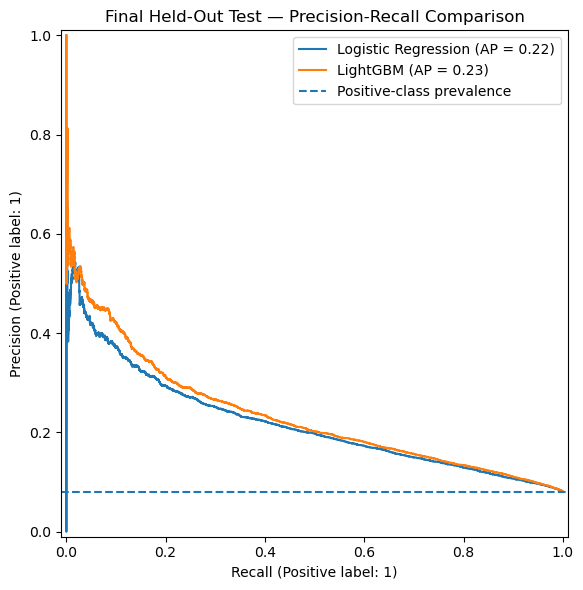

In [11]:
fig, ax = plt.subplots(figsize=(8, 6))

PrecisionRecallDisplay.from_predictions(
    y_test,
    logistic_test_prob,
    name="Logistic Regression",
    ax=ax
)

PrecisionRecallDisplay.from_predictions(
    y_test,
    test_prob,
    name="LightGBM",
    ax=ax
)

ax.axhline(
    y_test.mean(),
    linestyle="--",
    label="Positive-class prevalence"
)

ax.set_title(
    "Final Held-Out Test — Precision-Recall Comparison"
)
ax.legend()

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "day13_test_precision_recall.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

In [12]:
def bootstrap_metrics(
    y_true,
    probabilities,
    n_bootstrap=500,
    seed=42
):
    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)

    rng = np.random.default_rng(seed)
    n = len(y_true)

    rows = []

    for _ in range(n_bootstrap):
        indices = rng.integers(
            low=0,
            high=n,
            size=n
        )

        sample_y = y_true[indices]
        sample_prob = probabilities[indices]

        if len(np.unique(sample_y)) < 2:
            continue

        rows.append(
            evaluate_probabilities(
                sample_y, sample_prob
            )
        )

    results = pd.DataFrame(rows)

    summary = pd.DataFrame({
        "Mean": results.mean(),
        "CI_Lower": results.quantile(0.025),
        "CI_Upper": results.quantile(0.975)
    })

    return summary


lgbm_bootstrap = bootstrap_metrics(
    y_test,
    test_prob
)

logistic_bootstrap = bootstrap_metrics(
    y_test,
    logistic_test_prob
)

print("LightGBM:")
display(lgbm_bootstrap.round(4))

print("Logistic Regression:")
display(logistic_bootstrap.round(4))

LightGBM:


,Mean,CI_Lower,CI_Upper
ROC-AUC,0.7489,0.7421,0.7549
Average Precision,0.2334,0.2233,0.2441
Brier Score,0.0683,0.0667,0.0700


Logistic Regression:


,Mean,CI_Lower,CI_Upper
ROC-AUC,0.7383,0.7307,0.7449
Average Precision,0.2184,0.2089,0.2284
Brier Score,0.0690,0.0674,0.0707


In [13]:
rng = np.random.default_rng(42)

y_array = y_test.to_numpy()
n = len(y_array)

difference_rows = []

for _ in range(500):
    indices = rng.integers(0, n, n)

    sampled_y = y_array[indices]

    if np.unique(sampled_y).size < 2:
        continue

    lgbm_metrics = evaluate_probabilities(
        sampled_y,
        test_prob[indices]
    )

    logistic_metrics = evaluate_probabilities(
        sampled_y,
        logistic_test_prob[indices]
    )

    difference_rows.append({
        metric: (
            lgbm_metrics[metric]
            - logistic_metrics[metric]
        )
        for metric in lgbm_metrics
    })

difference_df = pd.DataFrame(difference_rows)

difference_summary = pd.DataFrame({
    "Mean_Difference": difference_df.mean(),
    "CI_Lower": difference_df.quantile(0.025),
    "CI_Upper": difference_df.quantile(0.975)
})

display(difference_summary.round(4))

,Mean_Difference,CI_Lower,CI_Upper
ROC-AUC,0.0106,0.0078,0.0133
Average Precision,0.0150,0.0103,0.0202
Brier Score,-0.0006,-0.0008,-0.0004


In [14]:
def evaluate_flags(y_true, flagged):
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        flagged,
        labels=[0, 1]
    ).ravel()

    return {
        "Reviewed": int(flagged.sum()),
        "Review_Rate": float(np.mean(flagged)),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
        "Precision": precision_score(
            y_true, flagged, zero_division=0
        ),
        "Recall": recall_score(
            y_true, flagged, zero_division=0
        )
    }


test_flags = test_prob >= SELECTED_THRESHOLD

threshold_test = evaluate_flags(
    y_test,
    test_flags
)

threshold_test["Threshold"] = SELECTED_THRESHOLD

threshold_test["Modeled_Cost"] = (
    threshold_test["Reviewed"] * 25
    + threshold_test["FN"] * 500
)

display(pd.Series(threshold_test))


Reviewed        2.783300e+04
Review_Rate     4.525470e-01
TP              3.856000e+03
FP              2.397700e+04
FN              1.109000e+03
TN              3.256100e+04
Precision       1.385406e-01
Recall          7.766365e-01
Threshold       6.000000e-02
Modeled_Cost    1.250325e+06
dtype: float64

In [15]:
def flag_top_fraction(probabilities, fraction):
    probabilities = np.asarray(probabilities)

    n = len(probabilities)
    k = int(np.floor(n * fraction))

    selected = np.argsort(
        -probabilities,
        kind="stable"
    )[:k]

    flagged = np.zeros(n, dtype=int)
    flagged[selected] = 1

    return flagged


test_top20_flags = flag_top_fraction(
    test_prob,
    SELECTED_REVIEW_CAPACITY
)

top20_test = evaluate_flags(
    y_test,
    test_top20_flags
)

top20_test["Capacity"] = SELECTED_REVIEW_CAPACITY

top20_test["Lift"] = (
    top20_test["Precision"] / y_test.mean()
)

top20_test["Modeled_Cost"] = (
    top20_test["Reviewed"] * 25
    + top20_test["FN"] * 500
)

assert top20_test["Reviewed"] <= int(
    np.floor(len(y_test) * SELECTED_REVIEW_CAPACITY)
)

display(pd.Series(top20_test))

Reviewed        1.230000e+04
Review_Rate     1.999902e-01
TP              2.484000e+03
FP              9.816000e+03
FN              2.481000e+03
TN              4.672200e+04
Precision       2.019512e-01
Recall          5.003021e-01
Capacity        2.000000e-01
Lift            2.501633e+00
Modeled_Cost    1.548000e+06
dtype: float64

In [16]:
val_threshold = evaluate_flags(
    y_val,
    val_prob >= SELECTED_THRESHOLD
)

val_top20 = evaluate_flags(
    y_val,
    flag_top_fraction(
        val_prob,
        SELECTED_REVIEW_CAPACITY
    )
)

policy_comparison = pd.DataFrame({
    "Validation — Threshold 0.06": val_threshold,
    "Test — Threshold 0.06": threshold_test,
    "Validation — Top 20%": val_top20,
    "Test — Top 20%": top20_test
}).T

display(
    policy_comparison[
        [
            "Reviewed",
            "Review_Rate",
            "TP",
            "FP",
            "FN",
            "Precision",
            "Recall"
        ]
    ].round(4)
)

,Reviewed,Review_Rate,TP,FP,FN,Precision,Recall
Validation — Threshold 0.06,27951.0,0.4545,3895.0,24056.0,1070.0,0.1394,0.7845
Test — Threshold 0.06,27833.0,0.4525,3856.0,23977.0,1109.0,0.1385,0.7766
Validation — Top 20%,12300.0,0.2000,2572.0,9728.0,2393.0,0.2091,0.5180
Test — Top 20%,12300.0,0.2000,2484.0,9816.0,2481.0,0.2020,0.5003


In [17]:
test_risk_df = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted_Risk": test_prob
})

test_risk_df["Decile"] = (
    pd.qcut(
        test_risk_df["Predicted_Risk"].rank(
            method="first"
        ),
        q=10,
        labels=False
    ).astype(int) + 1
)

overall_test_rate = test_risk_df["Actual"].mean()

test_deciles = (
    test_risk_df
    .groupby("Decile")
    .agg(
        Applicants=("Actual", "size"),
        Positive_Cases=("Actual", "sum"),
        Observed_Rate=("Actual", "mean"),
        Mean_Predicted_Risk=("Predicted_Risk", "mean")
    )
    .reset_index()
)

test_deciles["Lift"] = (
    test_deciles["Observed_Rate"] / overall_test_rate
)

display(test_deciles.round(4))

,Decile,Applicants,Positive_Cases,Observed_Rate,Mean_Predicted_Risk,Lift
0,1,6151,81,0.0132,0.0151,0.1631
1,2,6150,135,0.0220,0.0232,0.2719
2,3,6150,184,0.0299,0.0304,0.3706
3,4,6150,216,0.0351,0.0383,0.4351
4,5,6151,314,0.0510,0.0480,0.6324
5,6,6150,377,0.0613,0.0605,0.7594
6,7,6150,506,0.0823,0.0773,1.0192
7,8,6150,667,0.1085,0.1022,1.3435
8,9,6150,886,0.1441,0.1443,1.7846
9,10,6151,1599,0.2600,0.2697,3.2202


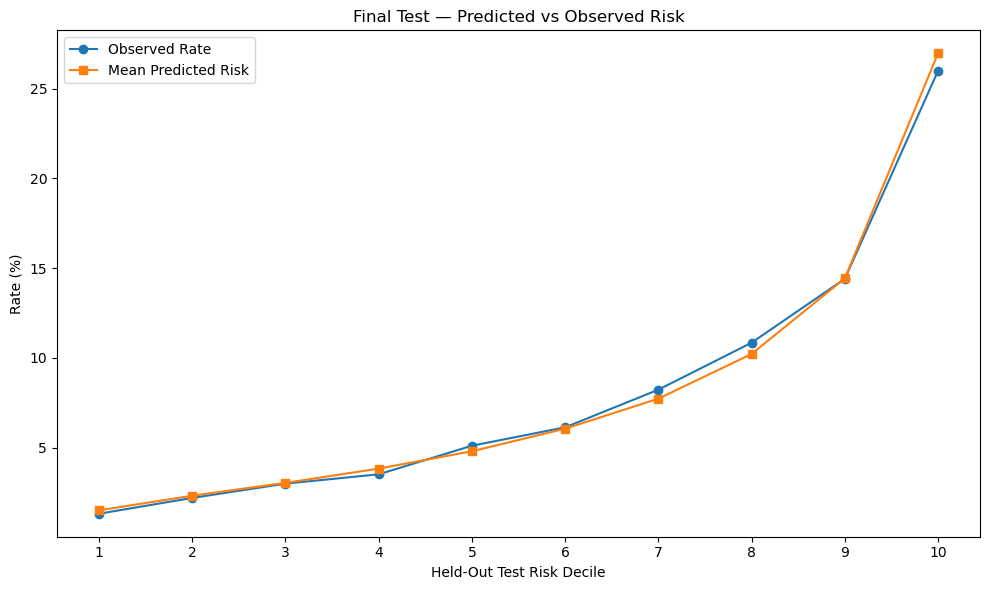

In [18]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    test_deciles["Decile"],
    test_deciles["Observed_Rate"] * 100,
    marker="o",
    label="Observed Rate"
)

ax.plot(
    test_deciles["Decile"],
    test_deciles["Mean_Predicted_Risk"] * 100,
    marker="s",
    label="Mean Predicted Risk"
)

ax.set_xlabel("Held-Out Test Risk Decile")
ax.set_ylabel("Rate (%)")
ax.set_title(
    "Final Test — Predicted vs Observed Risk"
)
ax.set_xticks(range(1, 11))
ax.legend()

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "day13_test_risk_deciles.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

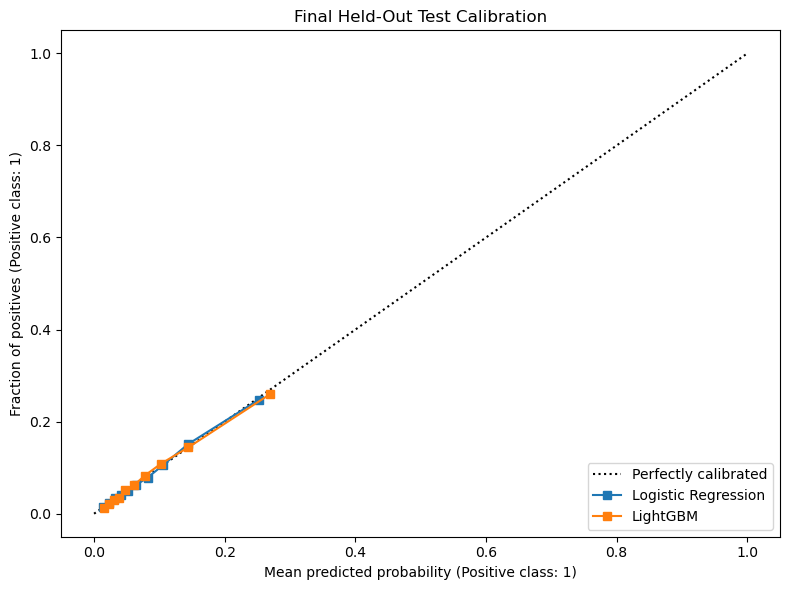

In [19]:
from sklearn.calibration import CalibrationDisplay

fig, ax = plt.subplots(figsize=(8, 6))

CalibrationDisplay.from_predictions(
    y_test,
    logistic_test_prob,
    n_bins=10,
    strategy="quantile",
    name="Logistic Regression",
    ax=ax
)

CalibrationDisplay.from_predictions(
    y_test,
    test_prob,
    n_bins=10,
    strategy="quantile",
    name="LightGBM",
    ax=ax
)

ax.set_title("Final Held-Out Test Calibration")

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "day13_test_calibration.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

In [20]:
final_metrics.to_csv(
    REPORT_DIR / "day13_final_model_metrics.csv"
)

generalization_df.to_csv(
    REPORT_DIR / "day13_generalization.csv",
    index=False
)

lgbm_bootstrap.to_csv(
    REPORT_DIR / "day13_lightgbm_confidence_intervals.csv"
)

difference_summary.to_csv(
    REPORT_DIR / "day13_model_difference_intervals.csv"
)

policy_comparison.to_csv(
    REPORT_DIR / "day13_policy_comparison.csv"
)

test_deciles.to_csv(
    REPORT_DIR / "day13_test_risk_deciles.csv",
    index=False
)

print("Day 13 evaluation results exported successfully.")

Day 13 evaluation results exported successfully.
